# TP 1.3 — KPI et visualisations Retail BI

Complément du notebook du cours, à lancer après `src/etl.py` ou `01_exploration.ipynb`.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
BASE_DIR = next((p for p in (Path.cwd(),Path.cwd().parent) if (p/'pyproject.toml').exists()),None)
if BASE_DIR is None: raise RuntimeError('Ouvrez le dossier du projet dans VS Code.')
csv = BASE_DIR/'data/clean/ventes.csv'
if not csv.exists(): raise FileNotFoundError('Lancez d’abord 01_exploration.ipynb ou uv run python src/etl.py')
ventes = pd.read_csv(csv, dtype={'InvoiceNo':'string','StockCode':'string'})
ventes['InvoiceDate'] = pd.to_datetime(ventes['InvoiceDate'])
ventes.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,montant
0,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
1,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850,United Kingdom,15.30
2,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850,United Kingdom,25.50
3,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850,United Kingdom,11.10
4,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850,United Kingdom,11.10


## 1. KPI du commerce


In [2]:
ca = ventes['montant'].sum()
factures = ventes['InvoiceNo'].nunique()
print('Chiffre d’affaires :', round(ca,2), '£')
print('Factures :', factures)
print('Références produit :', ventes['StockCode'].nunique())
print('Pays :', ventes['Country'].nunique())
print('Panier moyen :', round(ca/factures,2) if factures else 0, '£')
print('Clients identifiés :', ventes.loc[ventes['CustomerID'].notna() & (ventes['CustomerID'] != 0),'CustomerID'].nunique())

Chiffre d’affaires : 9345497.67 £
Factures : 19549
Références produit : 2868
Pays : 38
Panier moyen : 478.06 £
Clients identifiés : 4314


## 2. Chiffre d’affaires mensuel


,mois,montant
0,2010-12,681867.68
1,2011-01,582246.11
2,2011-02,452685.03
3,2011-03,619860.72
4,2011-04,457415.58
5,2011-05,669162.07
6,2011-06,678033.73
7,2011-07,616710.93
8,2011-08,659840.75
9,2011-09,957036.68


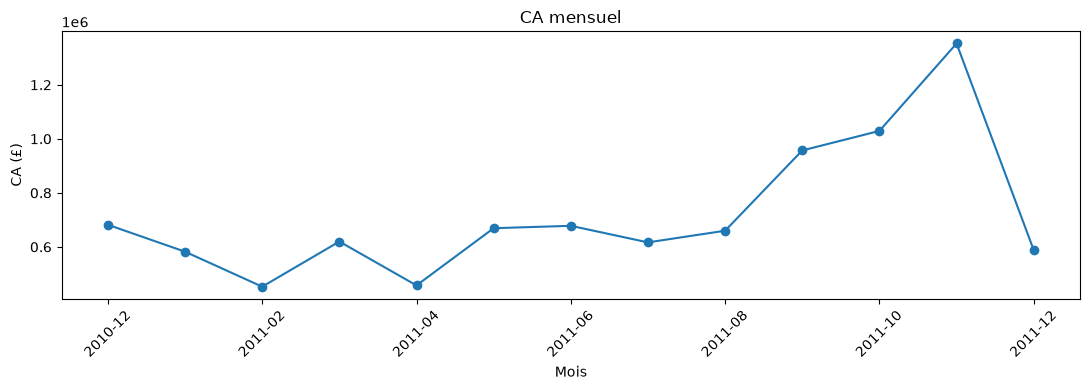

In [3]:
ventes['mois'] = ventes['InvoiceDate'].dt.to_period('M').astype(str)
ca_mensuel = ventes.groupby('mois',as_index=False)['montant'].sum().sort_values('mois')
display(ca_mensuel)
ax = ca_mensuel.plot(x='mois',y='montant',kind='line',marker='o',figsize=(11,4),legend=False)
ax.set(title='CA mensuel', xlabel='Mois', ylabel='CA (£)')
plt.xticks(rotation=45)
plt.tight_layout();plt.show()

## 3. Ventes par pays


,Country,montant
36,United Kingdom,7928438.03
24,Netherlands,269330.18
10,EIRE,255651.51
14,Germany,190013.20
13,France,174110.49
0,Australia,134003.12
33,Switzerland,48709.43
31,Spain,43028.49
20,Japan,35975.17
32,Sweden,35117.55


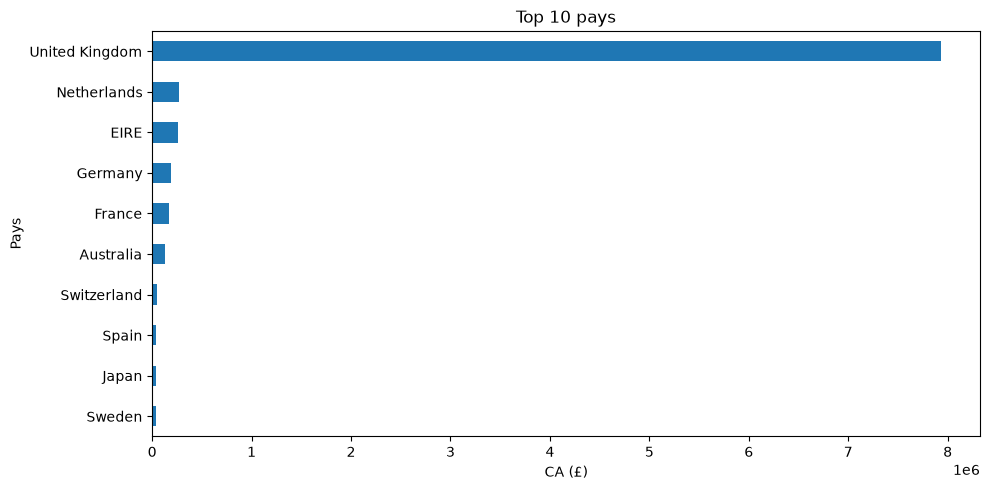

In [4]:
pays = ventes.groupby('Country',as_index=False)['montant'].sum().sort_values('montant',ascending=False)
display(pays.head(10))
ax = pays.head(10).iloc[::-1].plot(x='Country',y='montant',kind='barh',figsize=(10,5),legend=False)
ax.set(title='Top 10 pays',xlabel='CA (£)',ylabel='Pays')
plt.tight_layout();plt.show()

## 4. Top produits


,StockCode,Description,montant
1262,22423,REGENCY CAKESTAND 3 TIER,174156.54
2587,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60
2666,47566,PARTY BUNTING,99445.23
2042,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92
1948,23084,RABBIT NIGHT LIGHT,66870.03
944,22086,PAPER CHAIN KIT 50'S CHRISTMAS,64875.59
2872,84879,ASSORTED COLOUR BIRD ORNAMENT,58927.62
2734,79321,CHILLI LIGHTS,54096.36
2204,23298,SPOTTY BUNTING,42513.48
1229,22386,JUMBO BAG PINK POLKADOT,42401.01


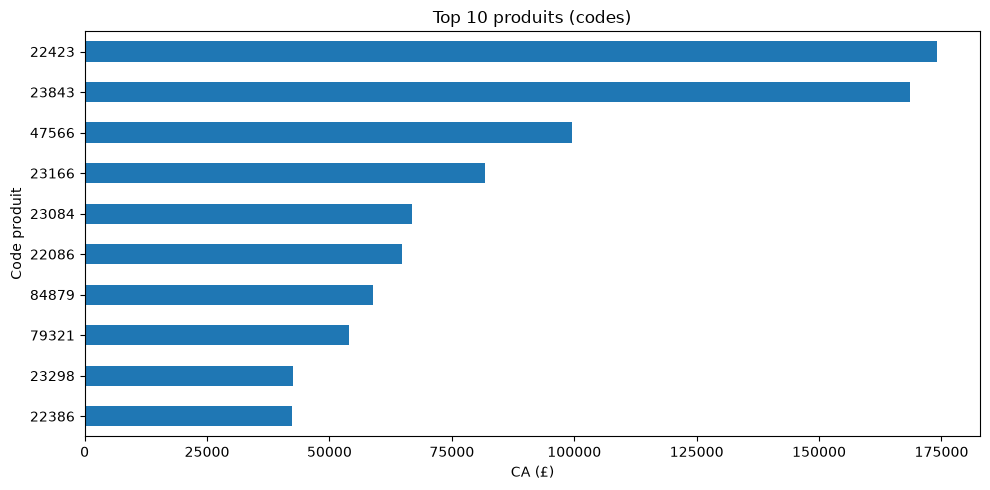

In [5]:
produits = ventes.groupby(['StockCode','Description'],as_index=False)['montant'].sum().sort_values('montant',ascending=False)
display(produits.head(10))
ax = produits.head(10).iloc[::-1].plot(x='StockCode',y='montant',kind='barh',figsize=(10,5),legend=False)
ax.set(title='Top 10 produits (codes)',xlabel='CA (£)',ylabel='Code produit')
plt.tight_layout();plt.show()

## 5. Exporter les tableaux de synthèse


In [6]:
output_dir = BASE_DIR/'data/marts'
output_dir.mkdir(parents=True, exist_ok=True)
ca_mensuel.to_csv(output_dir/'ca_mensuel.csv',index=False)
pays.to_csv(output_dir/'ca_par_pays.csv',index=False)
produits.head(10).to_csv(output_dir/'top_produits.csv',index=False)
print('Exports créés dans :',output_dir)

Exports créés dans : c:\Users\user\Downloads\Retail_BI_Arborescence_Prof (1)\tp2\data\marts
